## 1. Tổng quan Cấu trúc Bộ dữ liệu & Phân loại Đặc trưng

Bộ dữ liệu `dataset_B_05_2020.csv` gồm **11.430 mẫu (URL)** và **89 cột** (không có giá trị `NaN`/`Null` tường minh), được chia thành 4 nhóm chính:

| Nhóm cột | Số lượng | Danh sách cột tiêu biểu | Đặc điểm & Ghi chú xử lý ở bước Preprocessing |
| :--- | :--- | :--- | :--- |
| **Định danh & Nhãn mục tiêu** | 2 cột | `url` (chuỗi văn bản), `status` (`legitimate` / `phishing`) | Loại bỏ cột `url` (vì các đặc trưng cấu trúc URL đã được trích xuất thành số). Mã hóa nhị phân `status`: `legitimate` $\rightarrow 0$, `phishing` $\rightarrow 1$ (tập dữ liệu cân bằng hoàn hảo 5.715 mẫu mỗi lớp). |
| **Cột hằng số (Zero-Variance)** | 6 cột | `nb_or`, `ratio_nullHyperlinks`, `ratio_intRedirection`, `ratio_intErrors`, `submit_email`, `sfh` | Toàn bộ 11.430 dòng đều mang giá trị `0` (phương sai bằng `0`). Không mang thông tin phân loại và gây lỗi chia cho 0 khi chuẩn hóa $\rightarrow$ **Loại bỏ hoàn toàn**. |
| **Đặc trưng Nhị phân (Binary 0/1)** | 31 cột | `google_index`, `ip`, `domain_in_title`, `prefix_suffix`, `tld_in_subdomain`, `empty_title`, `https_token`, `punycode`, `port`, `shortening_service`, v.v. | Đã ở thang đo `{0, 1}` chuẩn. **Giữ nguyên giá trị 0/1**, không áp dụng `log1p` hay `StandardScaler`/`RobustScaler` để bảo toàn ý nghĩa xác suất/trạng thái bật-tắt. |
| **Đặc trưng Liên tục & Đếm (Continuous / Count)** | 50 cột | `length_url`, `length_hostname`, `nb_hyperlinks`, `domain_age`, `domain_registration_length`, `web_traffic`, `page_rank`, `ratio_digits_url`, `links_in_tags`, v.v. | Tồn tại 4 vấn đề lớn: **(1)** Giá trị khuyết ẩn âm (`-1`, `-2`, `-12`), **(2)** Không đồng nhất thang đo tỷ lệ `[0, 1]` vs `[0, 100]`, **(3)** Lệch phải cực đoan (Skewness $> 1.0$) & nhiều Outliers, **(4)** Đa cộng tuyến cao. |

## 2. Phân tích Đơn biến, Đa biến & Ghi chú Xử lý Chi tiết

### 2.1. Các vấn đề chất lượng dữ liệu (Data Quality Issues)
1. **Giá trị khuyết ẩn (Negative Sentinel Values `< 0`)**:
   - **`domain_age`**: Có **1.837 dòng (16,07%)** mang giá trị âm (`-1`: 1.781 dòng, `-2`: 55 dòng, `-12`: 1 dòng), gồm 994 mẫu `phishing` và 843 mẫu `legitimate` do không truy vấn được thông tin WHOIS.
   - **`domain_registration_length`**: Có **46 dòng** mang giá trị `-1` và **1.404 dòng** mang giá trị `0` (759 `phishing` vs 645 `legitimate`).
   - **Hướng xử lý**: Vì việc một tên miền ẩn hoặc không có thông tin WHOIS tự thân nó là một tín hiệu rủi ro, cần tạo thêm **2 biến cờ nhị phân** (`domain_age_unknown` và `domain_reg_len_unknown`), sau đó thay thế các giá trị $\le 0$ bằng **Median của các mẫu hợp lệ được tính riêng trên tập Train** (tránh dùng Mean vì phân phối lệch, và tuyệt đối không tính trên toàn bộ dữ liệu trước khi chia).
2. **Bất đồng nhất thang đo tỷ lệ (Scale Inconsistency `[0, 1]` vs `[0, 100]`)**:
   - Các cột `ratio_intHyperlinks`, `ratio_extHyperlinks`, `ratio_digits_url`, `ratio_digits_host`, `ratio_extErrors` nằm trong đoạn `[0.0, 1.0]`.
   - Ngược lại, 4 cột tỷ lệ phần trăm gồm `links_in_tags`, `ratio_intMedia`, `ratio_extMedia`, `safe_anchor` lại được lưu trên thang `[0.0, 100.0]`.
   - **Hướng xử lý**: Chia 4 cột phần trăm này cho `100.0` để đồng nhất toàn bộ các biến tỷ lệ về đoạn `[0.0, 1.0]`.
3. **Độ lệch phải (Right-Skewness) và Ngoại lai (Outliers)**:
   - Có **41/50 cột liên tục/đếm** có hệ số bất đối xứng $\text{Skewness} > 1.0$ (nhiều cột lệch cực đoan như `nb_dollar` $= 55.66$, `nb_percent` $= 35.42$, `nb_extCSS` $= 23.50$, `char_repeat` $= 15.76$, `longest_words_raw` $= 13.53$, `avg_word_path` $= 13.45$, `length_url` $= 8.09$, `nb_hyperlinks` $= 7.68$, `web_traffic` $= 2.78$).
   - **Hướng xử lý**:
     - Áp dụng phép biến đổi **`np.log1p(x)`** ($\ln(1 + x)$) cho các cột không âm có $\text{Skewness} > 1.0$ (kiểm tra trên tập Train). Sau khi biến đổi `log1p`, độ lệch giảm mạnh về gần phân phối chuẩn (ví dụ: `length_url` giảm từ `8.09` xuống `0.77`, `nb_hyperlinks` từ `7.68` xuống `-0.44`, `web_traffic` từ `2.78` xuống `0.09`, `char_repeat` từ `15.76` xuống `-0.05`).
     - Sử dụng **`RobustScaler`** (chuẩn hóa theo $\text{Median}$ và $\text{IQR} = Q_{75} - Q_{25}$, kết hợp fallback về độ lệch chuẩn $\sigma$ cho các cột đếm thưa có $\text{IQR} = 0$) để đưa mọi biến liên tục về cùng mặt bằng độ lớn mà không bị méo bởi các giá trị ngoại lai cực단.
4. **Phân tích Đa biến (Multivariate Analysis) & Đa cộng tuyến**:
   - **Đặc trưng đơn lẻ phân tách mạnh nhất với nhãn `status`**: `google_index` ($r = +0.7312$), `page_rank` ($r = -0.5111$), `nb_www` ($r = -0.4435$), `ratio_digits_url` ($r = +0.3564$), `domain_in_title` ($r = +0.3428$), `nb_hyperlinks` ($r = -0.3426$), `phish_hints` ($r = +0.3354$), `domain_age` ($r = -0.3319$), `ip` ($r = +0.3217$).
   - **Tương tác đa biến nổi bật**: Khi kết hợp `google_index = 1` và `page_rank` thấp (`0 - 1`), tỷ lệ URL là `phishing` lên tới **98,7%**.
   - **Các cặp đa cộng tuyến cao ($|r| > 0.80$)**:
     - `longest_words_raw` $\leftrightarrow$ `longest_word_path` ($r = 0.9685$)
     - `nb_and` $\leftrightarrow$ `nb_eq` ($r = 0.9064$)
     - `longest_word_host` $\leftrightarrow$ `avg_word_host` ($r = 0.8163$)
     - `shortest_word_host` $\leftrightarrow$ `avg_word_host` ($r = 0.8000$)
     - *Lưu ý*: Nếu bài toán tối ưu của bạn dùng mô hình tuyến tính (Logistic Regression, SVM tuyến tính) hoặc thuật toán chọn đặc trưng (Feature Selection bằng GA/PSO), việc xử lý hoặc lọc bớt các cặp có $|r| > 0.90$ sẽ giúp hội tụ nhanh và ổn định hơn.

## 3. DATA QUALITY

In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Đọc dữ liệu và kiểm tra tổng quan
df = pd.read_csv("../data/raw/dataset_B_05_2020.csv")
df['target'] = (df['status'] == 'phishing').astype(int)

print(f"Kích thước dữ liệu: {df.shape}")
print(f"Số lượng giá trị thiếu (NaN): {df.isnull().sum().sum()}")
print(f"Số dòng trùng lặp hoàn toàn: {df.duplicated().sum()}")
print(f"Số dòng trùng lặp đặc trưng (khác URL): {df.drop(columns=['url']).duplicated().sum()}")
print("\nPhân phối nhãn (status):")
print(df['status'].value_counts())

# 2. Phân loại các nhóm cột đặc trưng
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != 'target']
zero_var_cols = [c for c in num_cols if df[c].nunique() <= 1]
binary_cols = [c for c in num_cols if df[c].nunique() == 2 and set(df[c].unique()).issubset({0, 1})]
cont_cols = [c for c in num_cols if c not in zero_var_cols and c not in binary_cols]

print(f"\n- Cột hằng số (Zero-variance = {len(zero_var_cols)}): {zero_var_cols}")
print(f"- Cột nhị phân (Binary 0/1 = {len(binary_cols)}): {binary_cols}")
print(f"- Cột liên tục/đếm (Continuous/Count = {len(cont_cols)}): {cont_cols}")

# 3. Kiểm tra các giá trị âm (Sentinel values) và độ lệch (Skewness)
neg_cols = {c: (df[c] < 0).sum() for c in num_cols if (df[c] < 0).any()}
print("\nCác cột chứa giá trị âm (khuyết ẩn WHOIS):", neg_cols)

# 4. Kiểm tra các cặp đặc trưng đa cộng tuyến cao (|r| > 0.75)
active_cols = [c for c in num_cols if c not in zero_var_cols]
corr_matrix = df[active_cols].corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [
    (row, col, upper_tri.loc[row, col])
    for col in upper_tri.columns
    for row in upper_tri.index
    if upper_tri.loc[row, col] > 0.75
]
high_corr_pairs.sort(key=lambda x: x[2], reverse=True)
print("\nCác cặp đặc trưng có tương quan đa cộng tuyến cao (|r| > 0.75):")
for f1, f2, r_val in high_corr_pairs:
    print(f"  {f1:22s} <-> {f2:22s} : |r| = {r_val:.4f}")

Kích thước dữ liệu: (11430, 90)
Số lượng giá trị thiếu (NaN): 0
Số dòng trùng lặp hoàn toàn: 0
Số dòng trùng lặp đặc trưng (khác URL): 174

Phân phối nhãn (status):
status
legitimate    5715
phishing      5715
Name: count, dtype: int64

- Cột hằng số (Zero-variance = 6): ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']
- Cột nhị phân (Binary 0/1 = 31): ['ip', 'nb_tilde', 'nb_star', 'nb_dslash', 'https_token', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_external_redirection', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'login_form', 'external_favicon', 'iframe', 'popup_window', 'onmouseover', 'right_clic', 'empty_title', 'domain_in_title', 'domain_with_copyright', 'whois_registered_domain', 'dns_record', 'google_index']
- Cột liên tục/đếm (Continuous/Count = 50): ['length_url', 'length_hostname',

## 4. UNIVARIATE ANALYSIS

### 4.1. Continuous

In [ ]:
# ===========================================================
# SET UP         
# ===========================================================
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")                     
import pandas as pd
from src.eda.univariate import UnivariateAnalyzer

df = pd.read_csv("../data/raw/dataset_B_05_2020.csv")

nun = df.select_dtypes("number").nunique()
cont_cols = nun[nun > 2].index.tolist()
assert len(cont_cols) == 50, f"Kỳ vọng 50 cột, thực tế {len(cont_cols)}"

ua = UnivariateAnalyzer(df, cols=cont_cols)

In [ ]:
# ===========================================================
# BIẾN THỐNG KÊ MÔ TẢ
# ===========================================================
ua.summary()

,nunique,min,median,mean,max,n_neg,n_inf,pct_zero,skew,pct_outlier,flags
feature,,,,,,,,,,,
length_url,324,12.0,47.000000,61.126684,1.641000e+03,0,0,0.0,8.09,5.4,"HIGH_SKEW, MANY_OUTLIERS"
length_hostname,83,4.0,19.000000,21.090289,2.140000e+02,0,0,0.0,5.16,6.8,"HIGH_SKEW, MANY_OUTLIERS"
nb_dots,19,1.0,2.000000,2.480752,2.400000e+01,0,0,0.0,5.72,5.0,HIGH_SKEW
nb_hyphens,27,0.0,0.000000,0.997550,4.300000e+01,0,0,60.8,4.70,12.0,"ZERO_INFLATED, HIGH_SKEW, MANY_OUTLIERS"
nb_at,5,0.0,0.000000,0.022222,4.000000e+00,0,0,97.9,8.27,2.1,"LOW_CARDINALITY, ZERO_INFLATED, HIGH_SKEW"
nb_qm,4,0.0,0.000000,0.141207,3.000000e+00,0,0,86.4,2.49,13.6,"LOW_CARDINALITY, ZERO_INFLATED, HIGH_SKEW, MAN..."
nb_and,15,0.0,0.000000,0.162292,1.900000e+01,0,0,93.3,9.73,6.7,"ZERO_INFLATED, HIGH_SKEW, MANY_OUTLIERS"
nb_eq,16,0.0,0.000000,0.293176,1.900000e+01,0,0,86.3,6.53,13.7,"ZERO_INFLATED, HIGH_SKEW, MANY_OUTLIERS"
nb_underscore,17,0.0,0.000000,0.322660,1.800000e+01,0,0,85.2,7.27,14.8,"ZERO_INFLATED, HIGH_SKEW, MANY_OUTLIERS"


In [ ]:
# ===========================================================
# LỌC THEO FLAGS
# ===========================================================
flags = ["INF_VALUE", "NEGATIVE_VALUE", "HIGH_SKEW", "MANY_OUTLIERS", "ZERO_INFLATED"]
for fl in flags:
    cols = ua.filter_by_flag(fl)
    print(f"{fl} ({len(cols)} cột): {cols}\n")

print("Top 10 nhiều outlier nhất:", ua.top("pct_out", n=10))
print("Top 10 lệch nhất        :", ua.top("skew", n=10))

INF_VALUE (0 cột): []

NEGATIVE_VALUE (2 cột): ['domain_registration_length', 'domain_age']

HIGH_SKEW (42 cột): ['length_url', 'length_hostname', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_eq', 'nb_underscore', 'nb_percent', 'nb_slash', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_com', 'http_in_path', 'ratio_digits_url', 'ratio_digits_host', 'nb_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'statistical_report', 'nb_hyperlinks', 'ratio_extHyperlinks', 'nb_extCSS', 'ratio_extRedirection', 'ratio_extErrors', 'ratio_extMedia', 'domain_registration_length', 'web_traffic']

MANY_OUTLIERS (23 cột): ['length_url', 'length_hostname', 'nb_hyphens', 'nb_qm', 'nb_and', 'nb_eq', 'nb_underscore', 'nb_com', 'ratio_digits_url', 'ratio_digits_host', 'shortest_words_r

,nunique,min,median,mean,max,n_neg,n_inf,pct_zero,skew,pct_outlier,flags
feature,,,,,,,,,,,
length_url,324,12.0,47.000000,61.126684,1.641000e+03,0,0,0.0,8.09,5.4,"HIGH_SKEW, MANY_OUTLIERS"
length_hostname,83,4.0,19.000000,21.090289,2.140000e+02,0,0,0.0,5.16,6.8,"HIGH_SKEW, MANY_OUTLIERS"
nb_dots,19,1.0,2.000000,2.480752,2.400000e+01,0,0,0.0,5.72,5.0,HIGH_SKEW
nb_hyphens,27,0.0,0.000000,0.997550,4.300000e+01,0,0,60.8,4.70,12.0,"ZERO_INFLATED, HIGH_SKEW, MANY_OUTLIERS"
nb_at,5,0.0,0.000000,0.022222,4.000000e+00,0,0,97.9,8.27,2.1,"LOW_CARDINALITY, ZERO_INFLATED, HIGH_SKEW"
nb_qm,4,0.0,0.000000,0.141207,3.000000e+00,0,0,86.4,2.49,13.6,"LOW_CARDINALITY, ZERO_INFLATED, HIGH_SKEW, MAN..."
nb_and,15,0.0,0.000000,0.162292,1.900000e+01,0,0,93.3,9.73,6.7,"ZERO_INFLATED, HIGH_SKEW, MANY_OUTLIERS"
nb_eq,16,0.0,0.000000,0.293176,1.900000e+01,0,0,86.3,6.53,13.7,"ZERO_INFLATED, HIGH_SKEW, MANY_OUTLIERS"
nb_underscore,17,0.0,0.000000,0.322660,1.800000e+01,0,0,85.2,7.27,14.8,"ZERO_INFLATED, HIGH_SKEW, MANY_OUTLIERS"


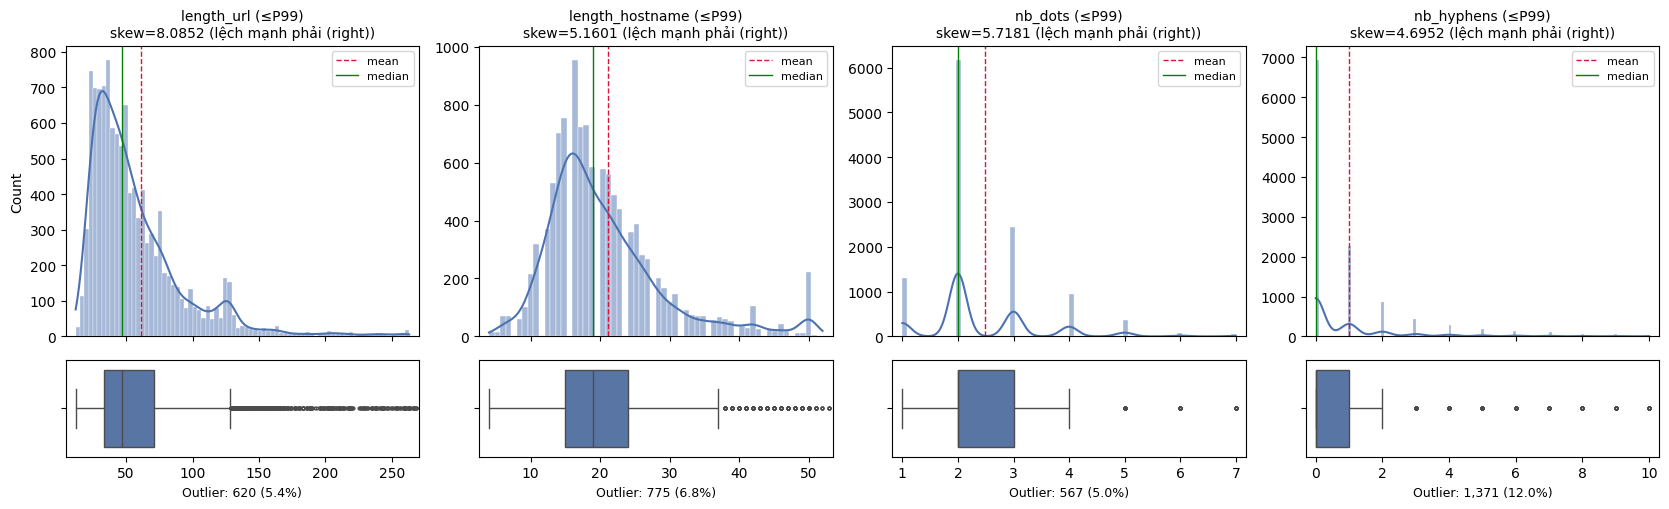

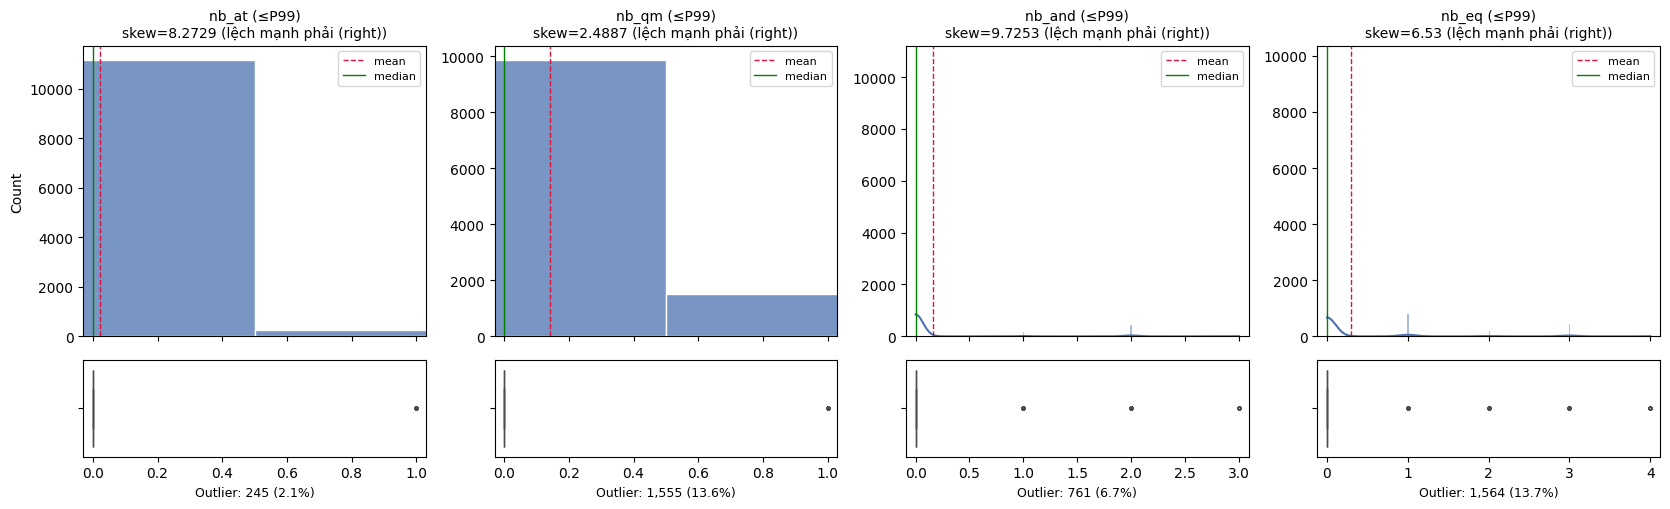

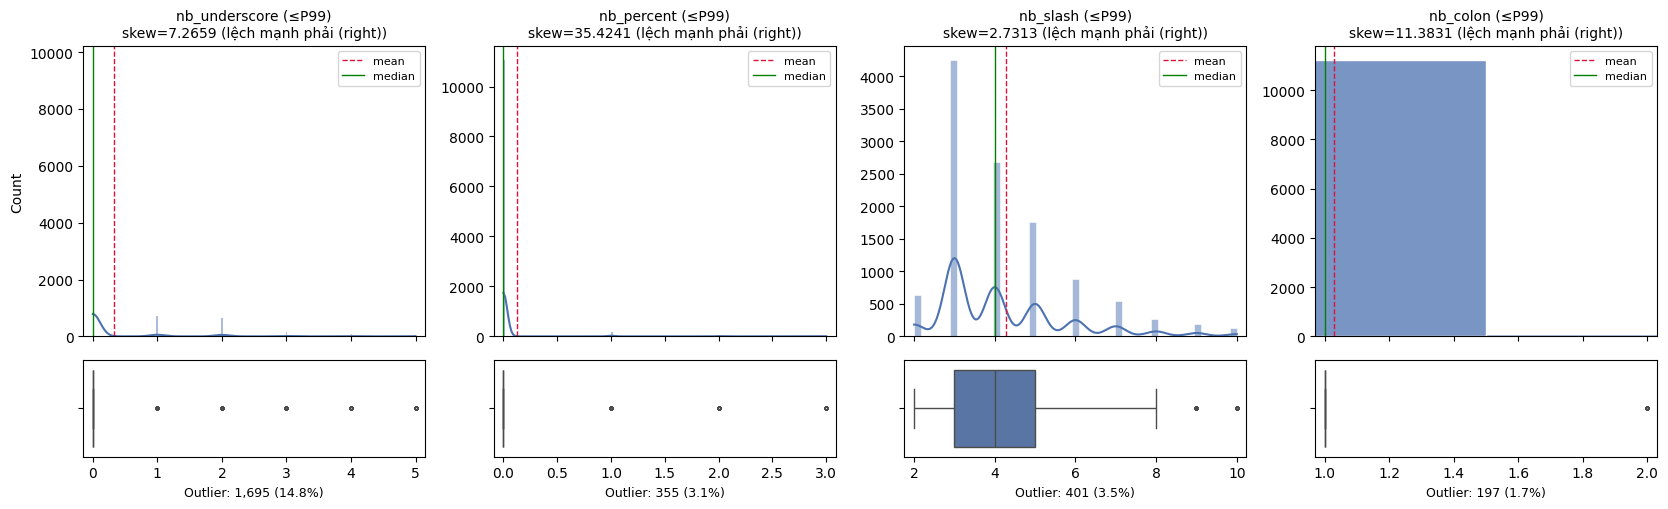

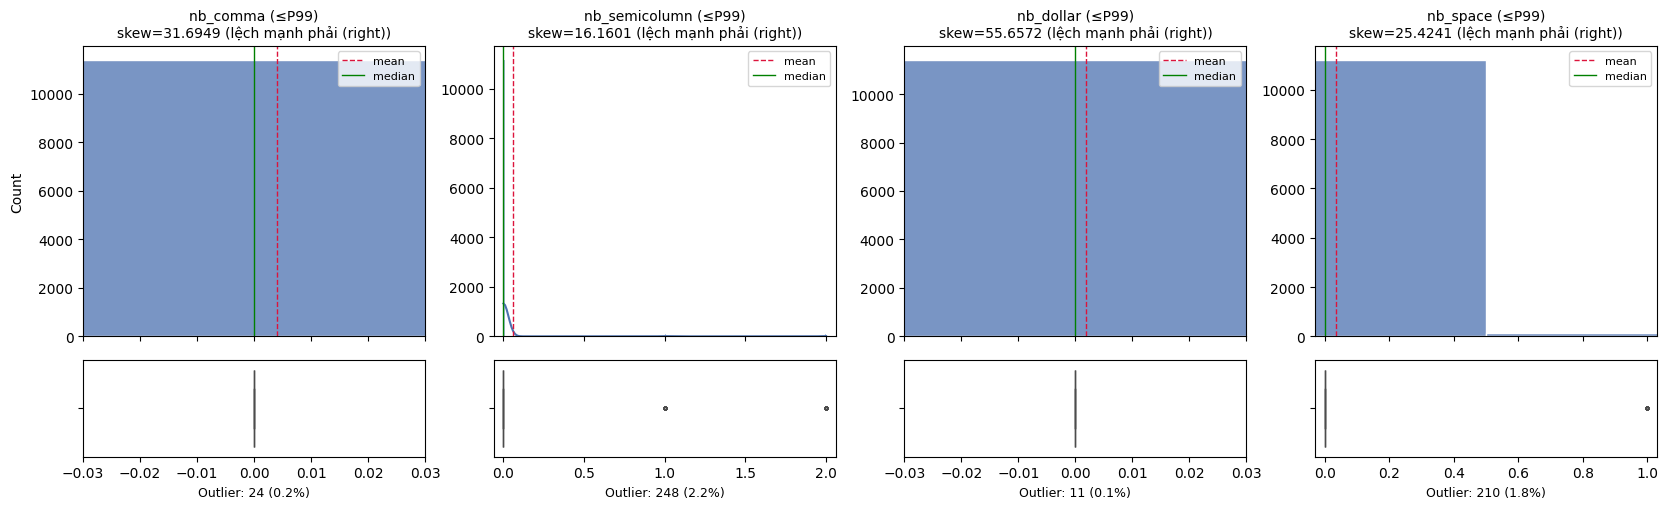

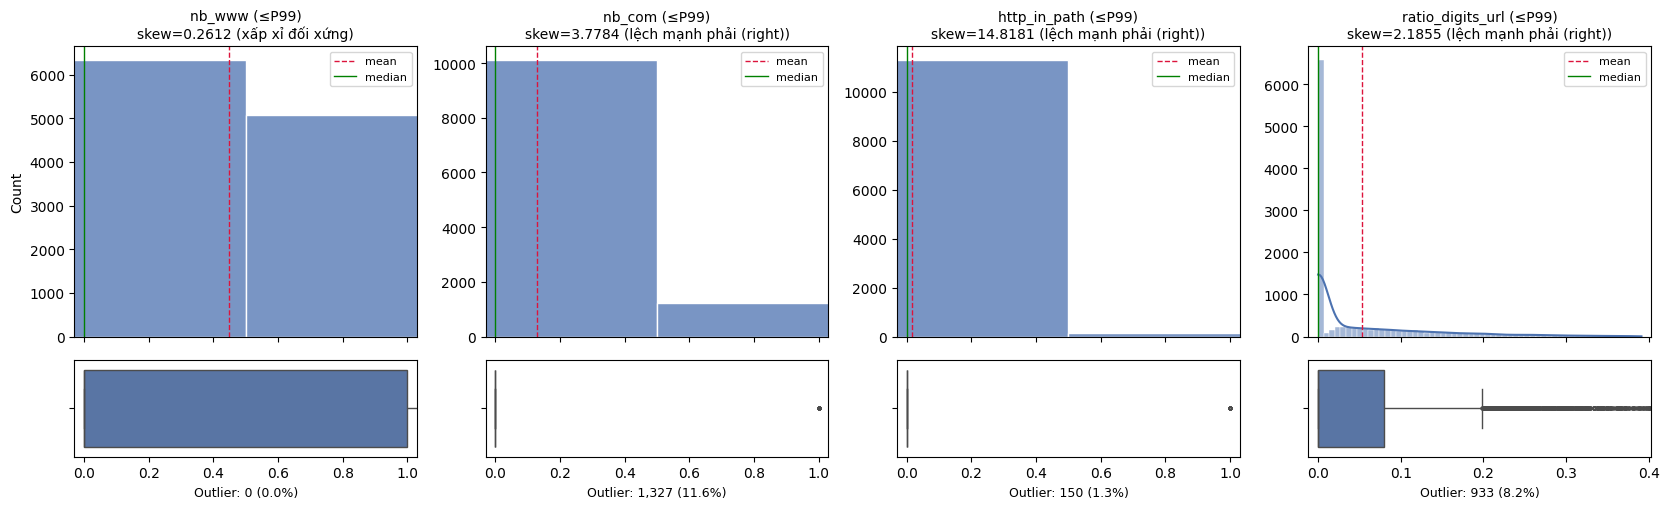

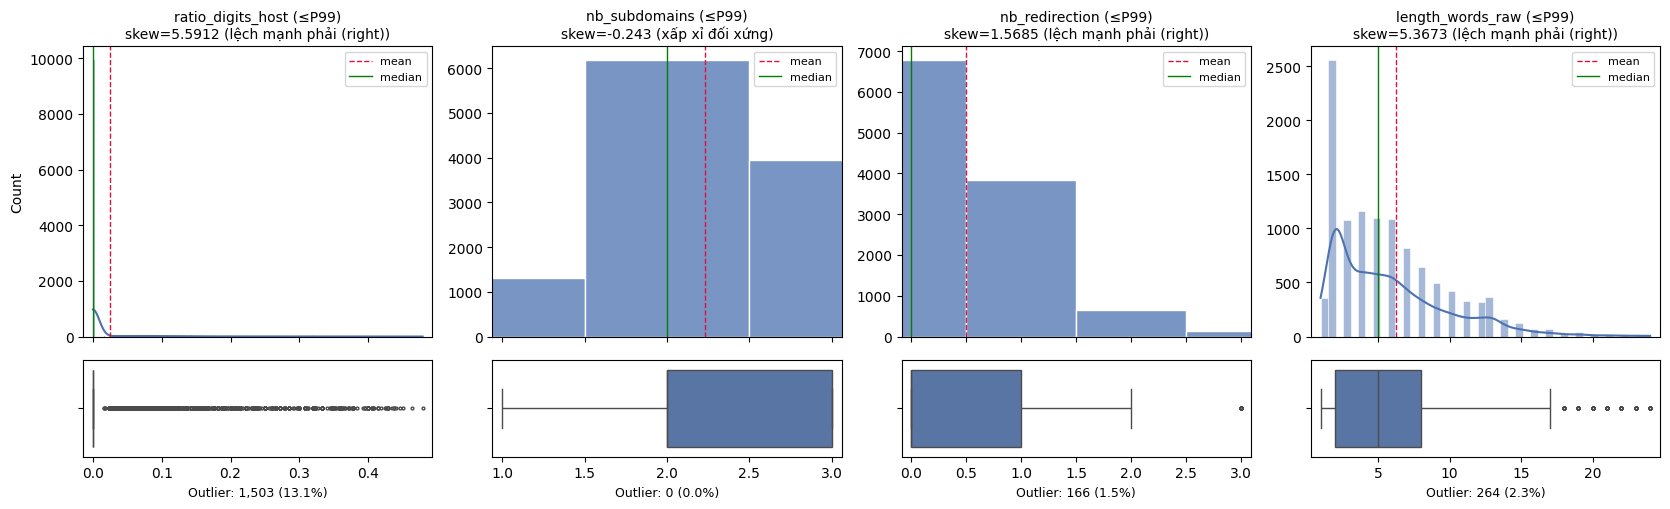

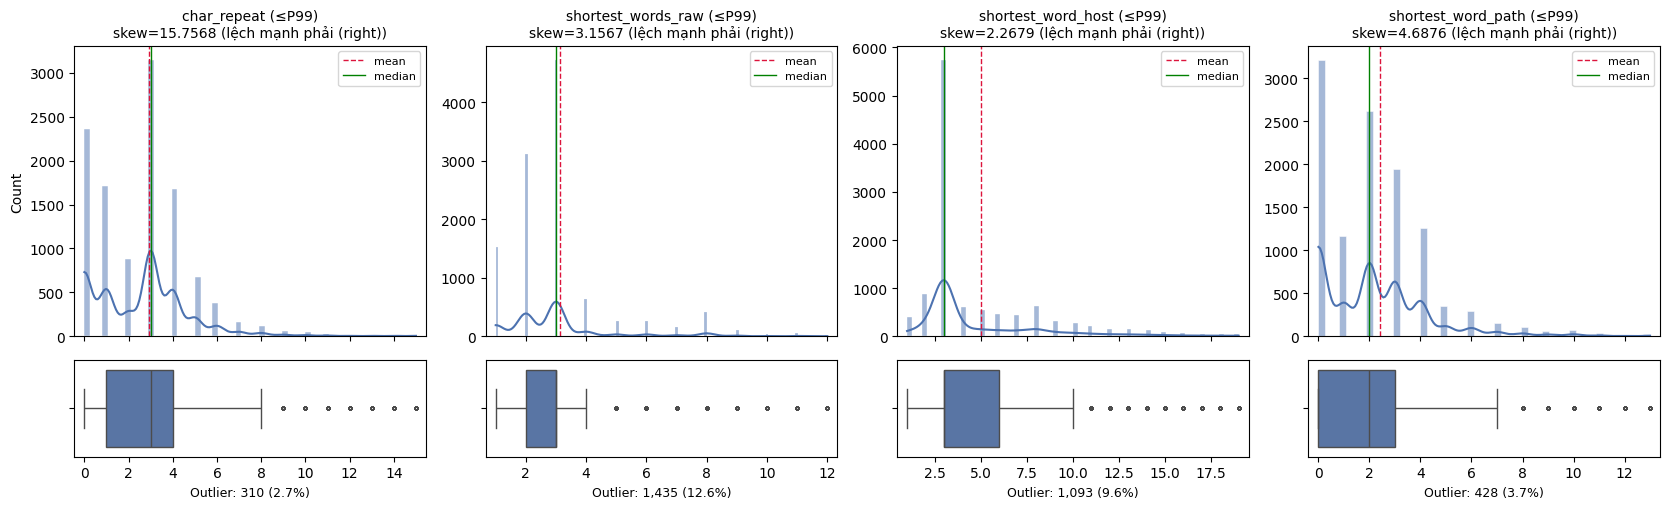

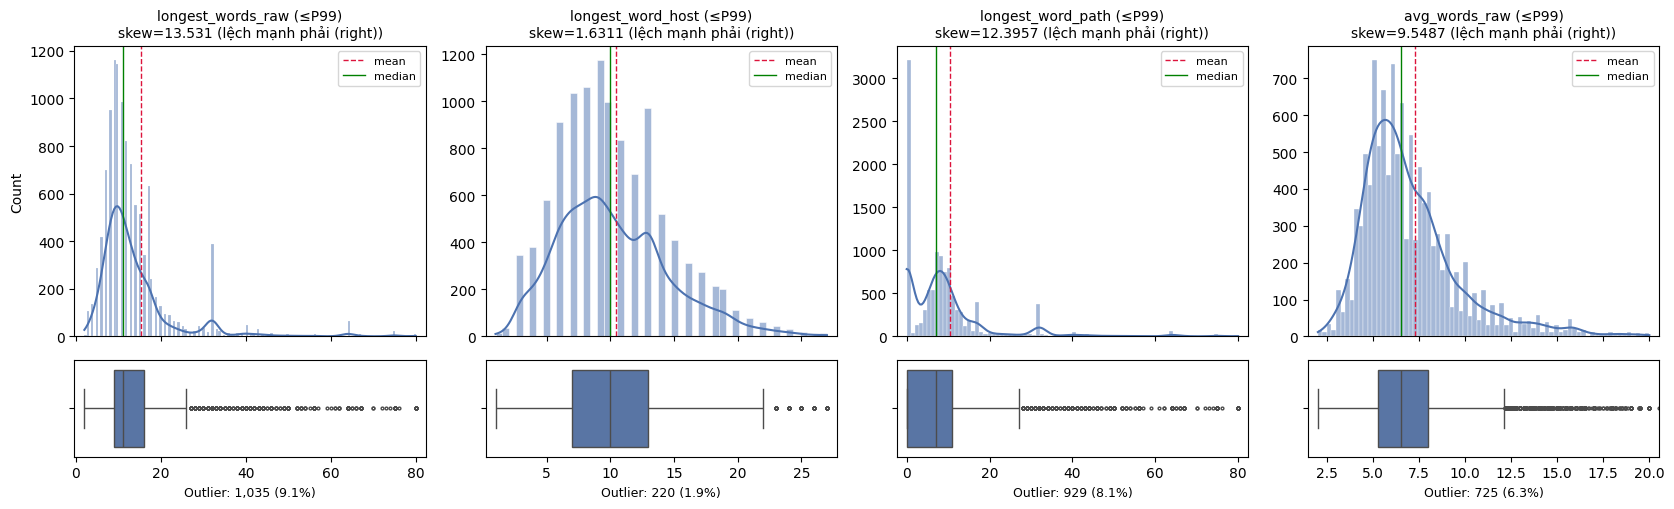

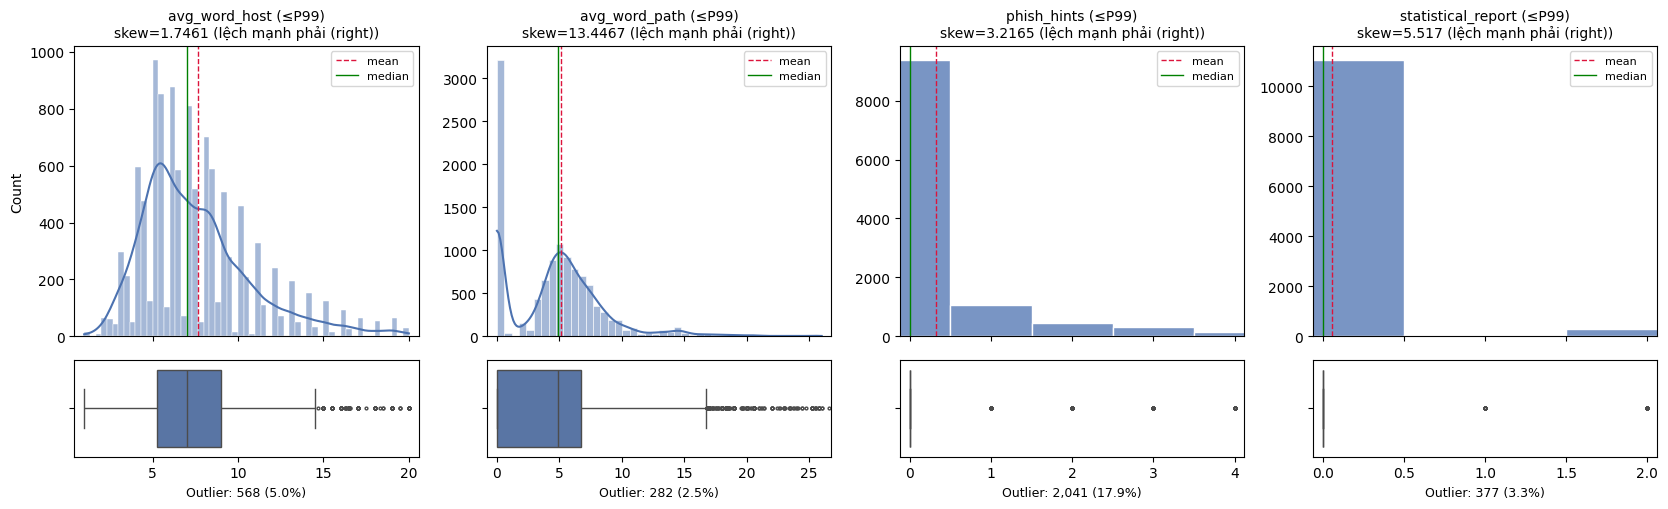

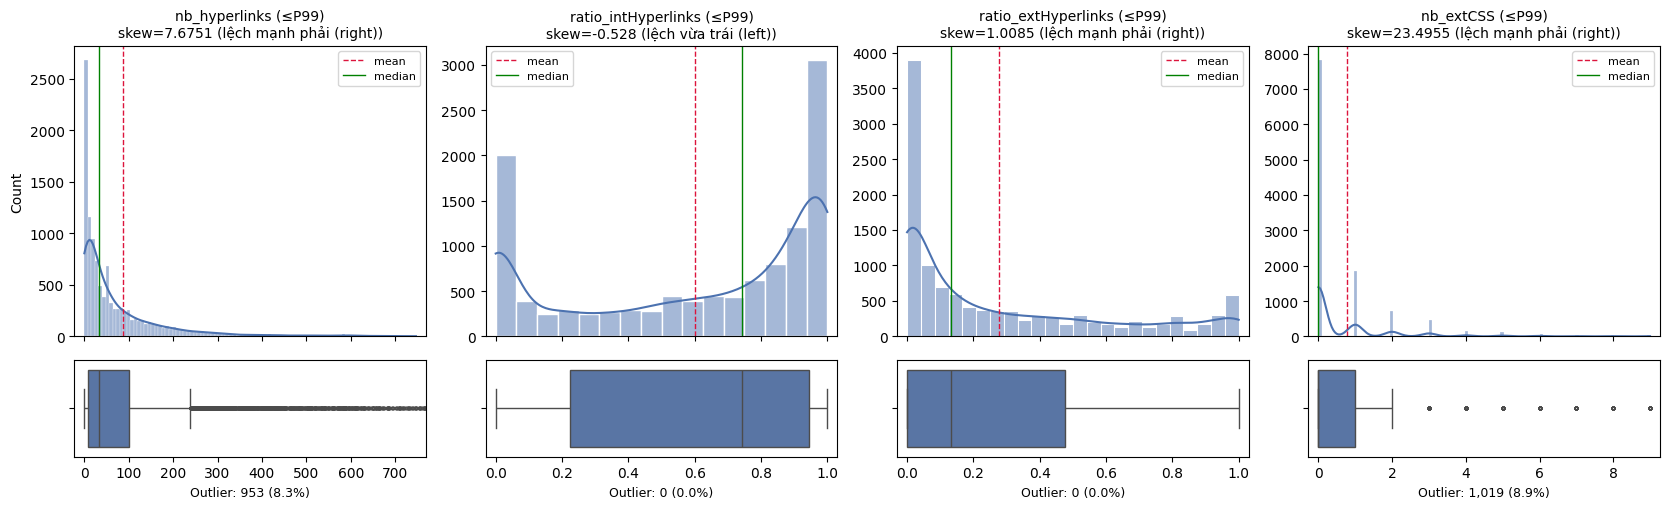

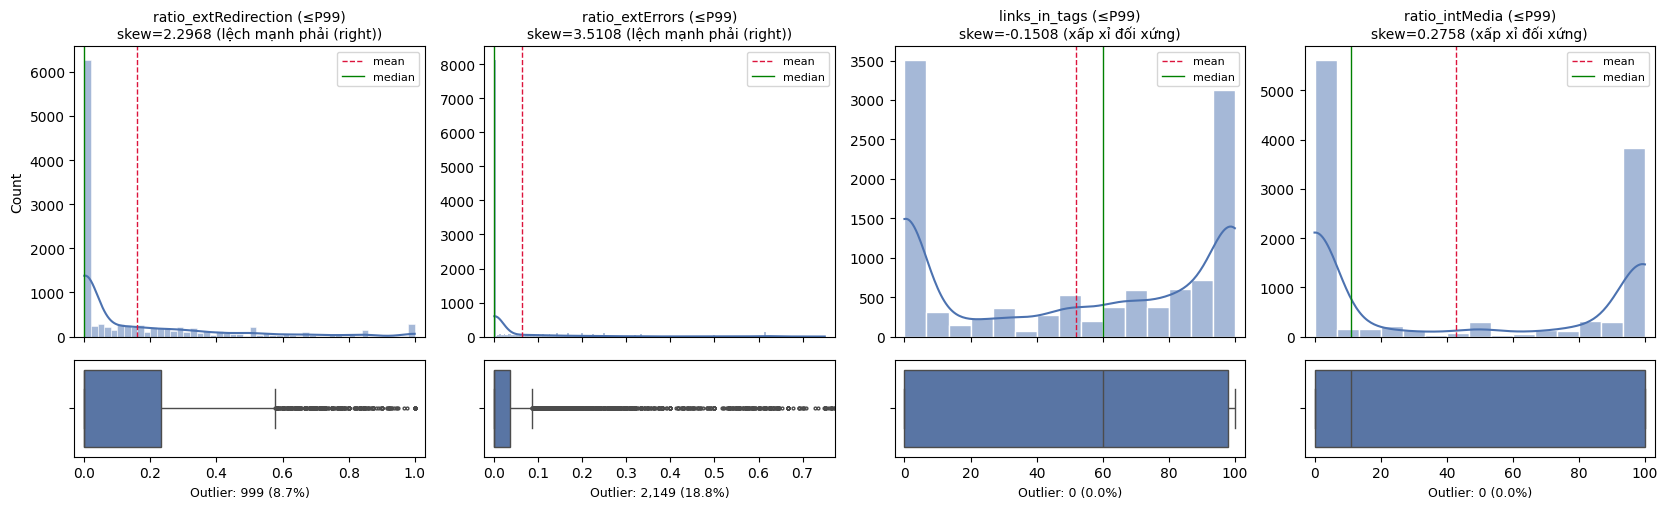

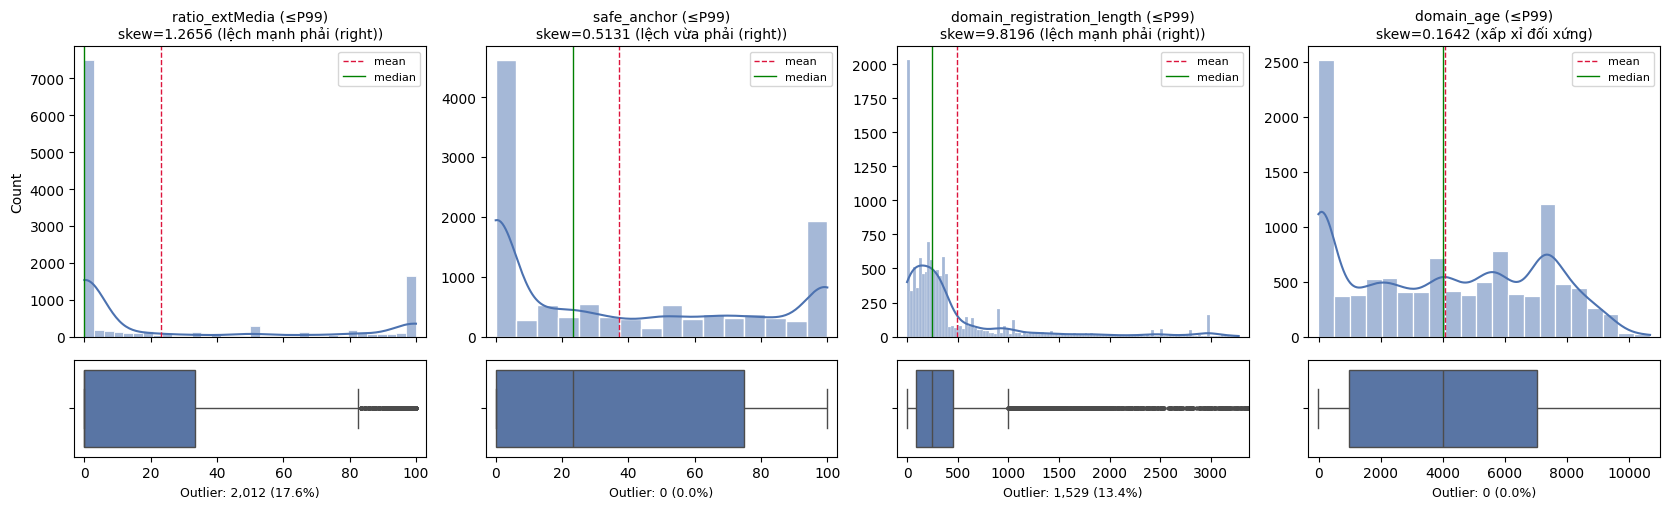

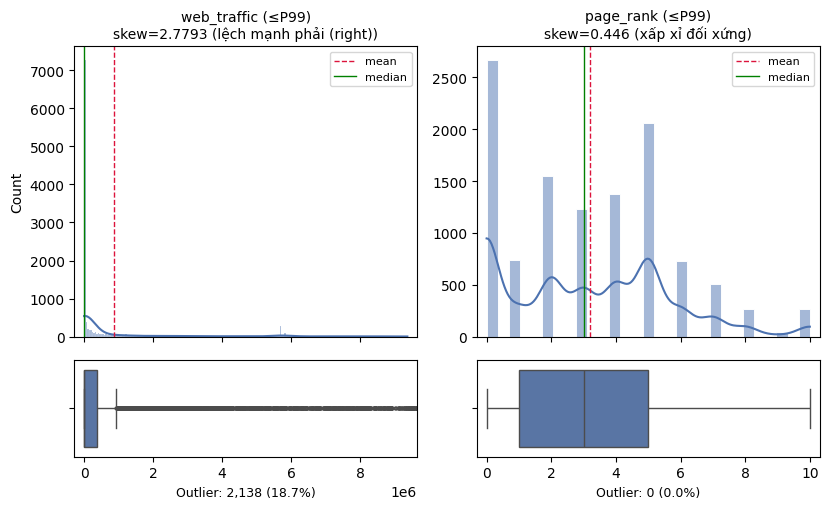

In [25]:
# ===========================================================
# BẢN PHÂN TÍCH CHI TIẾT
# ===========================================================
selected_cols = ['length_url', 'length_hostname', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_eq', 'nb_underscore', 'nb_percent', 'nb_slash', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 
                 'nb_space', 'nb_www', 'nb_com', 'http_in_path', 'ratio_digits_url', 'ratio_digits_host', 'nb_subdomains', 'nb_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 
                 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 
                 'ratio_extHyperlinks', 'nb_extCSS', 'ratio_extRedirection', 'ratio_extErrors', 'links_in_tags', 'ratio_intMedia', 'ratio_extMedia', 'safe_anchor', 'domain_registration_length', 'domain_age', 'web_traffic', 'page_rank'] # Chọn cột muốn kiểm tra tại đây

display(ua.summary(selected_cols))
_ = ua.plot(selected_cols, ncols=4, clip_upper_q=0.99)

### 4.2. Binary (Đã kiểm tra thống nhất toàn bộ 0/1)

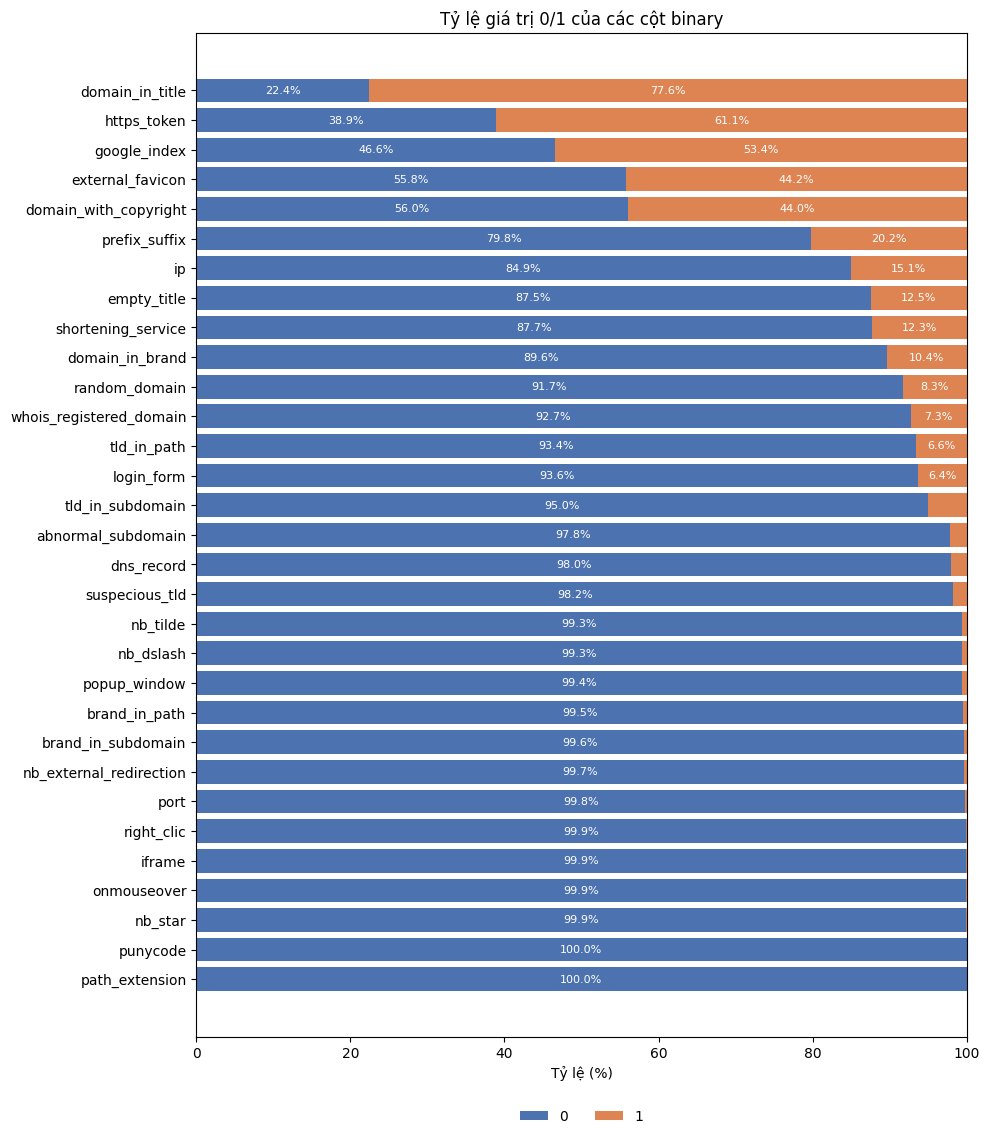

In [ ]:
# ===========================================================
# TỈ LỆ 0/1 CỦA CÁC CỘT BINARY
# ===========================================================
pct = (df[bin_cols].apply(lambda s: s.value_counts(normalize=True))
       .T.reindex(columns=[0, 1]).fillna(0) * 100)
pct = pct.sort_values(1)                          # sắp theo % của giá trị 1

fig, ax = plt.subplots(figsize=(10, 0.32 * len(pct) + 1.5))
ax.barh(pct.index, pct[0], color="#4C72B0", label="0")
ax.barh(pct.index, pct[1], left=pct[0], color="#DD8452", label="1")
for i, (p0, p1) in enumerate(zip(pct[0], pct[1])):
    if p0 > 6: ax.text(p0 / 2, i, f"{p0:.1f}%", ha="center", va="center", color="white", fontsize=8)
    if p1 > 6: ax.text(p0 + p1 / 2, i, f"{p1:.1f}%", ha="center", va="center", color="white", fontsize=8)
ax.set(xlim=(0, 100), xlabel="Tỷ lệ (%)", title="Tỷ lệ giá trị 0/1 của các cột binary")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.06), frameon=False)
plt.tight_layout(); plt.show()

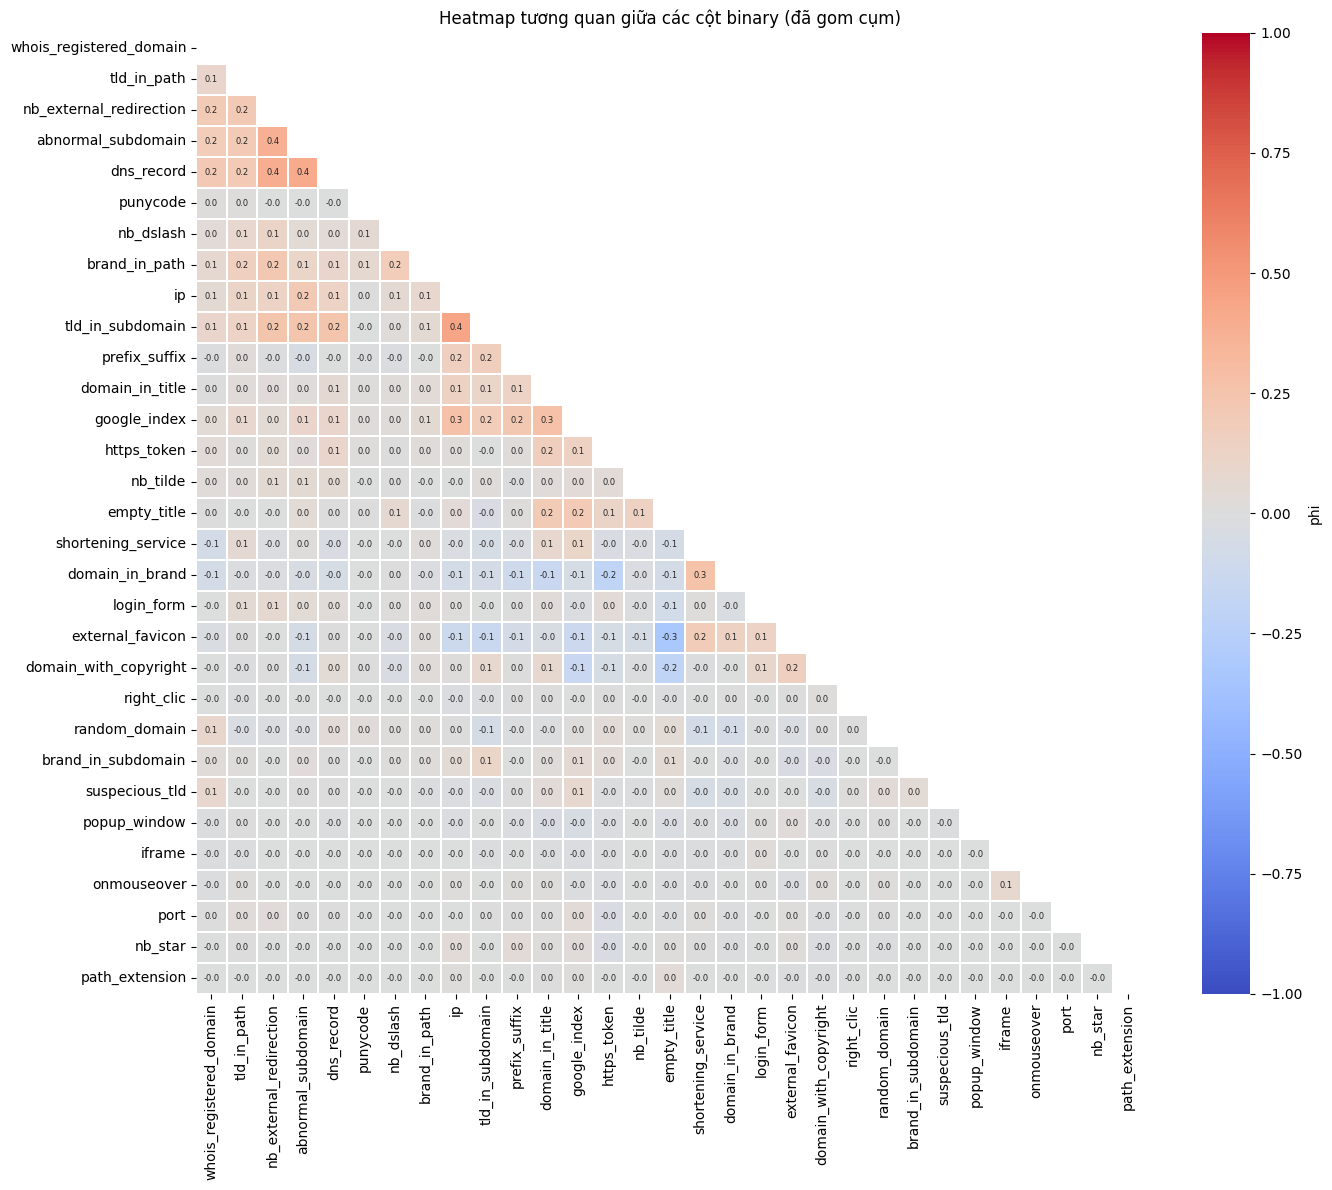

Cặp có |phi| >= 0.9: Không có


In [ ]:
# ===========================================================
# HEATMAP TƯƠNG QUAN GIỮA CÁC CỘT BINARY
# ===========================================================
THRESH = 0.9
corr = df[bin_cols].corr()                        # với biến 0/1, Pearson = hệ số phi
order = sns.clustermap(corr, method="average").dendrogram_row.reordered_ind
plt.close()
corr_o = corr.iloc[order, order]
mask = np.triu(np.ones_like(corr_o, dtype=bool))

plt.figure(figsize=(14, 12))
sns.heatmap(corr_o, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".1f", annot_kws={"size": 6}, linewidths=0.3,
            cbar_kws={"label": "phi"})
plt.title("Heatmap tương quan giữa các cột binary (đã gom cụm)")
plt.tight_layout(); plt.show()

# Cặp cột trùng/gần trùng thông tin
pairs = (corr.where(np.tril(np.ones(corr.shape, dtype=bool), -1)).stack()
         .rename("phi").reset_index().rename(columns={"level_0": "col_a", "level_1": "col_b"}))
pairs["agree_%"] = [100 * (df[a] == df[b]).mean() for a, b in zip(pairs.col_a, pairs.col_b)]
high = pairs[pairs.phi.abs() >= THRESH].sort_values("phi", key=abs, ascending=False)
print(f"Cặp có |phi| >= {THRESH}:", "Không có" if high.empty else "")
if not high.empty: print(high.round(3).to_string(index=False))

## 5. BIVARIATE ANALYSIS